# HR Analytics & Employee Attrition Prediction
EDA starter notebook for the IBM HR Analytics dataset.

In [5]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd()
DATA_PATH = ROOT / 'data' / 'WA_Fn-UseC_-HR-Employee-Attrition.csv'

# Search for CSV in the current folder and subfolders
if not DATA_PATH.exists():
    csv_files = list(ROOT.rglob('WA_Fn-UseC_-HR-Employee-Attrition.csv'))

    if csv_files:
        DATA_PATH = csv_files[0]
    else:
        raise FileNotFoundError(
            "IBM HR CSV file not found. Please upload the dataset."
        )

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Dataset shape: (1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [6]:
print('Shape:', df.shape)
display(df.info())
display(df.isna().sum().sort_values(ascending=False).head(10))
display(df['Attrition'].value_counts(dropna=False))

Shape: (1470, 35)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLev

None

Age                 0
Attrition           0
BusinessTravel      0
DailyRate           0
Department          0
DistanceFromHome    0
Education           0
EducationField      0
EmployeeCount       0
EmployeeNumber      0
dtype: int64

Attrition
No     1233
Yes     237
Name: count, dtype: int64

Observed attrition rate: 16.12%


,Attrition rate (%)
Department,
Sales,20.627803
Human Resources,19.047619
Research & Development,13.839750


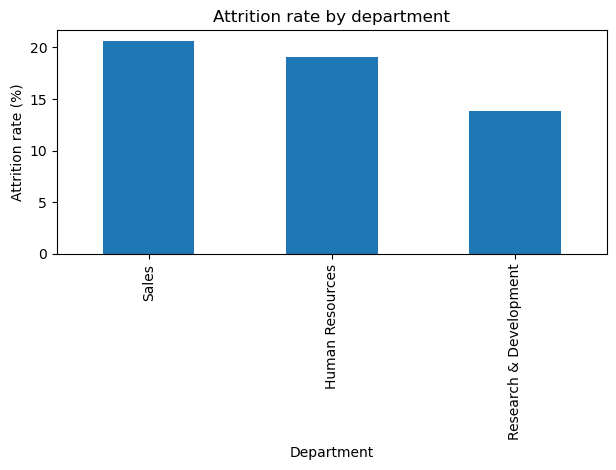

In [7]:
attrition_rate = (df['Attrition'].astype(str).str.lower().eq('yes').mean() * 100)
print(f'Observed attrition rate: {attrition_rate:.2f}%')
if 'Department' in df.columns:
    rate = df.assign(_left=df['Attrition'].astype(str).str.lower().eq('yes')).groupby('Department')['_left'].mean().mul(100).sort_values(ascending=False)
    display(rate.rename('Attrition rate (%)').to_frame())
    rate.plot(kind='bar', title='Attrition rate by department', ylabel='Attrition rate (%)')
    plt.tight_layout()
    plt.show()

In [8]:
# Train and compare Logistic Regression and Random Forest; saves the pipeline and reports.
from train_model import train_and_save
results = train_and_save(df, root_dir=ROOT)
pd.DataFrame(results['metrics']).sort_values('f1', ascending=False)

,model,accuracy,precision,recall,f1,roc_auc
0,Logistic Regression,0.751701,0.348837,0.638298,0.451128,0.803170
1,Random Forest,0.836735,0.470588,0.170213,0.250000,0.798605
